In [10]:
##Imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
import itertools

import torch
import torch.fft as fft
import torchoptics
from torchoptics.profiles import gaussian, circle
from torchoptics.elements import PhaseModulator
from torchoptics import Field, System
from pyhank import HankelTransform
device = "cuda" if torch.cuda.is_available() else "cpu"

1st part: create a lens by reducing the problem to 1d thanks to the radial simmetry

In [11]:

import numpy as np


class RadialASM:
    """
    Radially symmetric Angular Spectrum Method.

    Uses a zeroth-order QDHT to perform radial propagation.
    Assumes transformer.kr is expressed in rad/m.
    """

    def __init__(self, transformer, wl, z):
        self.transformer = transformer
        self.wl = wl
        self.z = z

        self.k = 2 * np.pi / wl
        self.kr = transformer.kr

        # Longitudinal wavevector, including evanescent components
        self.kz = np.sqrt(
            (self.k**2 - self.kr**2).astype(complex)
        )

        # Forward propagation transfer function
        self.H = np.exp(1j * self.kz * z)

        # Adjoint propagation transfer function
        self.H_adj = np.conj(self.H)

    def propagate(self, U):
        """Forward propagation from z=0 to z."""
        spectrum = self.transformer.qdht(U)
        return self.transformer.iqdht(spectrum * self.H)

    def backpropagate(self, U):
        """Apply the adjoint propagation operator."""
        spectrum = self.transformer.qdht(U)
        return self.transformer.iqdht(spectrum * self.H_adj)


def Binary_IFTA_1D(
    inputProfile,
    goalFunction,
    transformer,
    propagator,
    maxiter=150
):
    r = transformer.r

    # Radial integration weights: r dr
    weights = r * np.gradient(r)

    # Power normalization
    P_in = np.sum(weights * np.abs(inputProfile)**2)
    P_goal = np.sum(weights * np.abs(goalFunction)**2)

    A_tgt = goalFunction * np.sqrt(P_in / P_goal)

    # Initialize binary phase {0, pi}
    phi = np.random.choice(
        [0.0, np.pi],
        size=inputProfile.shape
    )

    for i in range(maxiter):

        # DOE plane
        E1 = inputProfile * np.exp(1j * phi)

        # Propagate to working plane
        E2 = propagator.propagate(E1)

        # Enforce target amplitude
        E20 = A_tgt * np.exp(1j * np.angle(E2))

        # Apply adjoint propagation
        E10 = propagator.backpropagate(E20)

        # Binary phase update
        ds = np.real(E1 * E10)

        toggle_mask = ds < 0
        phi = np.where(toggle_mask, np.pi - phi, phi)

    return phi


class Binary_DOE_1D:

    def __init__(self, params):

        self.wl = params["wl"]
        self.z = params["z"]          # Working-plane distance

        self.rmax = params["rmax"]
        self.N = params["N"]

        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def makeProfiles(self, p=4):

        # Zeroth-order quasi-discrete Hankel transform
        self.transformer = HankelTransform(
            order=0,
            max_radius=self.rmax,
            n_points=self.N
        )

        self.r = self.transformer.r
        self.kr = self.transformer.kr

        # Incident Gaussian amplitude
        self.inputAmp = np.exp(-(self.r / self.w0)**2)

        # Target amplitude at the actual working plane
        self.goalProfile = np.exp(
            -(self.r / self.wgoal)**(2 * p)
        )

        # Initialize radial ASM propagator
        self.propagator = RadialASM(
            transformer=self.transformer,
            wl=self.wl,
            z=self.z
        )

    def makeDOE(self, maxiter=150):

        self.DOE = Binary_IFTA_1D(
            self.inputAmp,
            self.goalProfile,
            self.transformer,
            self.propagator,
            maxiter=maxiter
        )

    def getDOE(self):
        return self.DOE

    def getWorkingField(self):

        E0 = self.inputAmp * np.exp(1j * self.DOE)

        return self.propagator.propagate(E0)


From a radius, create the lenses by using different 'interpolation techniques'

In [12]:

def radial_to_2d(profile, radial_grid, N, rmax):

    shape = 2 * N - 1

    # Must match the spacing used by the PyTorch propagation
    dx = rmax / N

    coords = (
        np.arange(shape) - (shape - 1) / 2
    ) * dx

    X, Y = np.meshgrid(coords, coords, indexing='ij')

    R = np.sqrt(X**2 + Y**2)

    # Interpolate using the actual QDHT radial coordinates
    profile_2d = np.interp(
        R.ravel(),
        radial_grid,
        profile,
        left=profile[0],
        right=profile[-1]
    ).reshape(shape, shape)

    return profile_2d

def genLensPhase(N, wl, fl, dx):
    y, x = np.ogrid[-(N - 1):N, -(N - 1):N]
    r = np.sqrt(x ** 2 + y ** 2) * dx
    return -np.pi * r ** 2 / (wl * fl)


def create_interspersed_doe(DOEs: list, mirror: bool = False):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    g = 2 * radius_len
    merged_radius = np.zeros(radius_len)

    for r in range(radius_len):
        if mirror:
            cycle_len = 2 * n
            rem = r % cycle_len
            lens_idx = rem if rem < n else (cycle_len - 1 - rem)
        else:
            lens_idx = r % n
        profile = DOEs[lens_idx]
        merged_radius[r] = profile[r] if r < len(profile) else profile[-1]

    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]
    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.round(r_grid).astype(int)
    r_indices = np.clip(r_indices, 0, radius_len - 1)
    doe_grid = merged_radius[r_indices]
    return merged_radius, doe_grid


def create_permuted_sector_doe(DOEs: list, a: float):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    padded_DOEs = []
    for doe in DOEs:
        if len(doe) < radius_len:
            padded_DOEs.append(np.pad(doe, (0, radius_len - len(doe)), mode='edge'))
        else:
            padded_DOEs.append(doe[:radius_len])

    orig_stack = np.vstack(padded_DOEs)
    perms = list(itertools.permutations(range(n)))
    num_perms = len(perms)
    r_idx = np.arange(radius_len)
    base_lens_indices = r_idx % n

    aux_DOEs = []
    for p in perms:
        p_array = np.array(p)
        permuted_lens_indices = p_array[base_lens_indices]
        aux_radius = orig_stack[permuted_lens_indices, r_idx]
        aux_DOEs.append(aux_radius)

    num_sectors_exact = 360.0 / a
    num_sectors = int(np.round(num_sectors_exact))
    g = 2 * radius_len
    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]

    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.clip(np.round(r_grid).astype(int), 0, radius_len - 1)

    theta_grid = np.arctan2(y - center, x - center)
    theta_deg = np.degrees(theta_grid) % 360

    sector_idx = np.clip(np.floor(theta_deg / a).astype(int), 0, num_sectors - 1)
    aux_idx = sector_idx % num_perms
    aux_stack = np.vstack(aux_DOEs)
    doe_grid = aux_stack[aux_idx, r_indices]
    return doe_grid

Create and show the lenses

Generating baseline 1D GS DOEs...


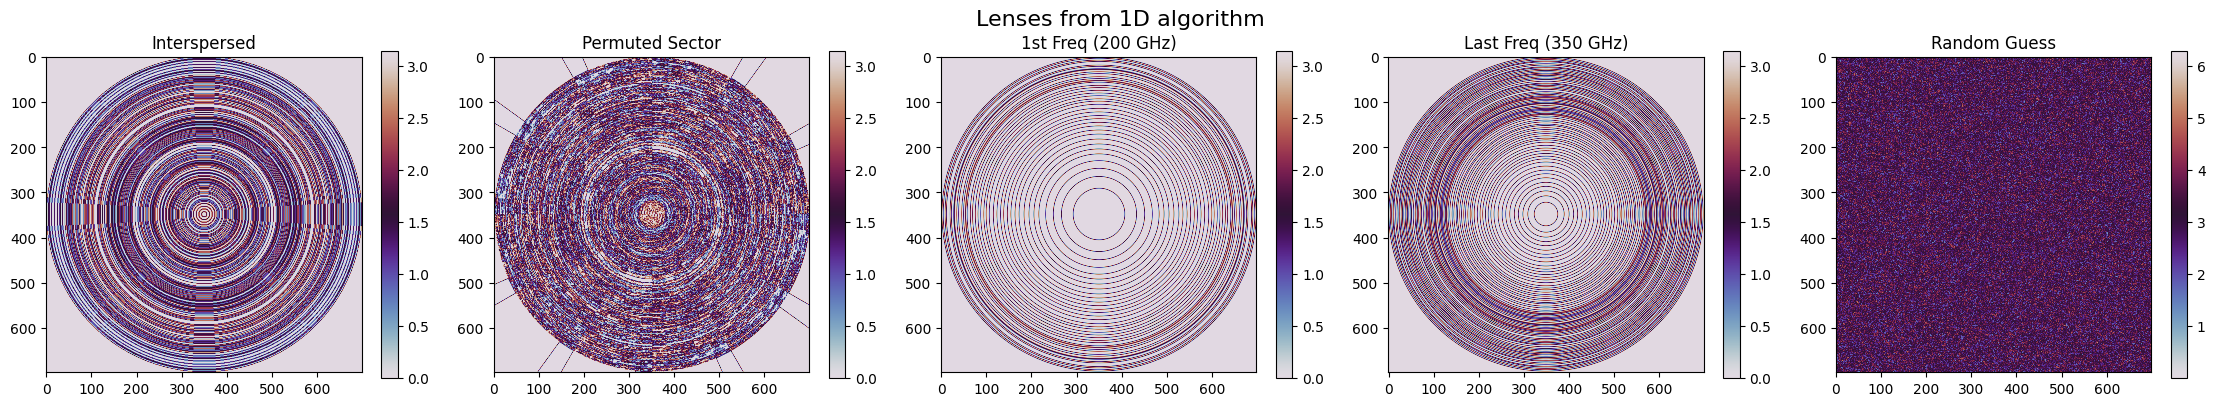

In [13]:

# ---------------------------------------------
# Generate Initial 1D Profiles 
# ---------------------------------------------
print("Generating baseline 1D GS DOEs...")
f0 = 200 * 1e9
does = []
radial_grid = None
for i in range(0, 6, 1):
    f = f0 + i * 30 * 1e9
    initial_doe = []
    params = {
        "z": 15e-2,  # meters
        "wl": 3e8 / f,  # meters
        "rmax": 10e-2,  # meters
        "N": 350,
        "w0": 0.02,  # meters
        "wgoal": 0.008  # meters
    }
    
    
    DOE_maker = Binary_DOE_1D(params)
    DOE_maker.makeProfiles(p=4)
    DOE_maker.makeDOE(maxiter=150)
    does.append(DOE_maker.getDOE())
    
    if radial_grid is None:
        radial_grid = DOE_maker.r.copy()
# Get specific 2D DOEs for PyTorch Initialization
_, prova1 = create_interspersed_doe(does)
prova1 = prova1[:-1, :-1]  # Crop to 699x699

prova3 = create_permuted_sector_doe(does, 360 / 1440)
prova3 = prova3[:-1, :-1]

does_0_2d = radial_to_2d(
    does[0],
    radial_grid,
    N=350,
    rmax=0.1
)
does_end_2d = radial_to_2d(
    does[-1],
    radial_grid,
    N=350,
    rmax=0.1
)

# --- NEW: Generate Random Phase Lens ---
shape_2d = 2 * params['N'] - 1
random_doe_2d = np.random.uniform(0, 2 * np.pi, size=(shape_2d, shape_2d))

# Lists to iterate for optimization (Added Random Lens)
initial_DOEs = [prova1, prova3, does_0_2d, does_end_2d, random_doe_2d]
titles = ["Interspersed", "Permuted Sector", "1st Freq (200 GHz)", "Last Freq (350 GHz)", "Random Guess"]

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, initial_DOEs, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Lenses from 1D algorithm", fontsize=16)
plt.tight_layout()
plt.show()


2nd part: 2d algorithm to optimize without symetry

Option 2: a more complex Loss function that takes into account the different regions of the plane, so can give more weight to the central region, but also assigns different weights to the average over frequencies and to the worse frequency.

In [14]:

# ==========================================
# PROGRAM 2: PYTORCH MULTI-FREQUENCY BINARY DOE OPTIMIZATION
# ANGULAR SPECTRUM PROPAGATION (2D ASM)
# BINARY PHASE STATES: 0 AND PI
# ==========================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

from torch import fft


print("\nStarting 2D Multi-Frequency Binary Optimization (ASM)...")


# ==========================================
# 1. PARAMETERS
# ==========================================

dx = params['rmax'] / params['N']

shape_2d = 2 * params['N'] - 1

torchoptics.set_default_spacing(dx)

M = shape_2d
center_idx = M // 2

fl = params['z']
wgoal = params['wgoal']

frequencies = [
    f0 + i * 30e9 for i in range(6)
]

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]

num_frequencies = len(frequencies)


# ==========================================
# 2. BINARY PHASE MODEL
# ==========================================

# Available models:
#
# "physical_relief":
# Phase difference between the two physical
# thicknesses scales with frequency.
#
# "fixed_0_pi":
# The phase states remain exactly 0 and pi
# at every frequency (ideal achromatic model).

binary_phase_model = "physical_relief"


def binary_phase_scale(f):

    if binary_phase_model == "physical_relief":

        return f / f0

    elif binary_phase_model == "fixed_0_pi":

        return 1.0

    else:

        raise ValueError("Unknown binary phase model")


def get_binary_phase(binary_state, f):

    return (
        torch.pi *
        binary_state *
        binary_phase_scale(f)
    )


# ==========================================
# 3. SOURCE PROFILE
# ==========================================

source_profile = gaussian(
    shape_2d,
    waist_radius=params['w0']
).to(device, dtype=torch.float32)

# Incident power at the DOE plane
P_in = torch.sum(
    torch.abs(source_profile)**2
) * dx**2


# ==========================================
# 4. CENTERED FOURIER TRANSFORMS
# ==========================================

def centered_fft2(E):
    """2D FFT with the zero spatial frequency at the array centre."""
    return fft.fftshift(
        fft.fft2(fft.ifftshift(E))
    )


def centered_ifft2(E):
    """Inverse of centered_fft2."""
    return fft.fftshift(
        fft.ifft2(fft.ifftshift(E))
    )


# ==========================================
# 5. ANGULAR SPECTRUM PROPAGATION (2D ASM)
# ==========================================

# In the original Fraunhofer model, `fl` was the propagation distance
# used to map spatial frequencies to physical working-plane coordinates.
# Here it is used as the actual free-space propagation distance z.
# The input and output ASM planes have the same sampling interval dx.
#
# Zero-padding reduces circular-wraparound artefacts from the FFT. The
# returned field is cropped back to (M, M), so all downstream array shapes
# and output containers remain unchanged. Set the factor to 1 to disable
# padding (at the cost of a greater risk of wraparound).
ASM_PAD_FACTOR = 2


class AngularSpectrumPropagator2D:
    """FFT-based scalar angular-spectrum propagator on a fixed grid."""

    def __init__(self, grid_size, spacing, propagation_distance,
                 device, pad_factor=2):
        if pad_factor < 1 or int(pad_factor) != pad_factor:
            raise ValueError("pad_factor must be a positive integer")

        self.M = int(grid_size)
        self.dx = float(spacing)
        self.z = float(propagation_distance)
        self.device = device
        self.pad_factor = int(pad_factor)

        # Keep an odd padded grid and preserve the original centre pixel.
        self.Np = self.pad_factor * (self.M - 1) + 1
        self.pad = (self.Np - self.M) // 2

        # Frequency coordinates in cycles/m, centred to match centered_fft2.
        fx = fft.fftshift(
            fft.fftfreq(
                self.Np,
                d=self.dx,
                device=self.device
            )
        ).to(torch.float32)

        FX, FY = torch.meshgrid(fx, fx, indexing="ij")

        # Transverse wave-vector components in rad/m.
        self.KX = 2.0 * torch.pi * FX
        self.KY = 2.0 * torch.pi * FY

        # Cache frequency-dependent transfer functions because the same
        # frequencies are used repeatedly during IFTA and final evaluation.
        self._transfer_cache = {}

    def _pad(self, E):
        if self.pad == 0:
            return E
        return F.pad(
            E,
            (self.pad, self.pad, self.pad, self.pad),
            mode="constant",
            value=0.0
        )

    def _crop(self, E):
        if self.pad == 0:
            return E
        return E[
            self.pad:self.pad + self.M,
            self.pad:self.pad + self.M
        ]

    def _get_transfer_functions(self, f):
        key = float(f)
        if key not in self._transfer_cache:
            c = 3e8
            wavelength = c / key
            k = 2.0 * torch.pi / wavelength

            kz_squared = k**2 - self.KX**2 - self.KY**2

            # Complex square root also handles evanescent components:
            # for kx^2 + ky^2 > k^2, kz = +i*alpha and exp(i*kz*z)
            # decays as exp(-alpha*z).
            kz = torch.sqrt(kz_squared.to(torch.complex64))
            H = torch.exp(1j * kz * self.z)

            self._transfer_cache[key] = (H, torch.conj(H))

        return self._transfer_cache[key]

    def forward(self, E1, f):
        """Propagate the field from z=0 to z using the angular spectrum."""
        H, _ = self._get_transfer_functions(f)
        E1_padded = self._pad(E1)
        spectrum = centered_fft2(E1_padded)
        E2_padded = centered_ifft2(spectrum * H)
        return self._crop(E2_padded)

    def adjoint(self, E2, f):
        """Apply the adjoint of the cropped forward propagation operator.

        This is the stable back-propagation operator for the IFTA update.
        It equals the inverse for propagating components; evanescent
        components are not exponentially amplified.
        """
        _, H_adj = self._get_transfer_functions(f)

        # The adjoint of output cropping is zero-padding before propagation.
        E2_padded = self._pad(E2)
        spectrum = centered_fft2(E2_padded)
        E10_padded = centered_ifft2(spectrum * H_adj)

        # The adjoint of input zero-padding is cropping.
        return self._crop(E10_padded)


asm_propagator = AngularSpectrumPropagator2D(
    grid_size=M,
    spacing=dx,
    propagation_distance=fl,
    device=device,
    pad_factor=ASM_PAD_FACTOR
)


def asm_forward(E1, f):
    return asm_propagator.forward(E1, f)


def asm_backward(E2, f):
    return asm_propagator.adjoint(E2, f)


# ==========================================
# 6. WORKING-PLANE TARGETS ON THE ASM GRID
# ==========================================

# Standard FFT-based ASM uses the same sample spacing in the input and
# output planes. Therefore, unlike Fraunhofer propagation, the output
# coordinates are NOT lambda*fl times the DOE-plane FFT frequencies.
axis_work = (
    torch.arange(M, device=device, dtype=torch.float32) - center_idx
) * dx

XW, YW = torch.meshgrid(
    axis_work, axis_work, indexing="ij"
)
RW = torch.sqrt(XW**2 + YW**2)

# Store targets, masks and sampling intervals. Keep the original list name
# `focal_plane_spacings` so the later evaluation/resampling code remains
# compatible; in ASM every entry is simply dx.
target_masks = []
target_amplitudes = []
target_intensities = []

center_masks = []
outer_masks = []
background_masks = []

focal_plane_spacings = []

# Regional radii
center_radius = 0.5 * wgoal

# The target circle must fit inside the sampled working-plane window.
max_axis_radius = float(axis_work[-1].item())
if wgoal > max_axis_radius:
    print(
        "[WARNING] wgoal exceeds the working-plane half-width "
        f"({wgoal:.4e} m > {max_axis_radius:.4e} m). "
        "The circular target will be clipped by the ASM grid."
    )

for f in frequencies:

    # ASM output sampling is the same for every frequency.
    dxf = dx
    focal_plane_spacings.append(dxf)

    # --------------------------------------
    # Circular uniform target in physical x-y coordinates
    # --------------------------------------

    target_mask_f = (
        RW <= wgoal
    ).to(torch.float32)

    # Physical target area (discrete approximation)
    P_tgt = torch.sum(target_mask_f) * dxf**2

    if P_tgt.item() <= 0:
        raise ValueError(
            f"Target contains no pixels at {f/1e9:.1f} GHz. "
            "Increase the spatial resolution or target radius."
        )

    # Target amplitude normalized to incident power
    A_tgt_f = (
        target_mask_f *
        torch.sqrt(P_in / P_tgt)
    )

    I_tgt_f = A_tgt_f**2

    target_masks.append(target_mask_f)
    target_amplitudes.append(A_tgt_f)
    target_intensities.append(I_tgt_f)

    # --------------------------------------
    # Regional masks
    # --------------------------------------

    center_masks.append(
        (RW <= center_radius).to(torch.float32)
    )

    outer_masks.append(
        (
            (RW > center_radius) &
            (RW <= wgoal)
        ).to(torch.float32)
    )

    background_masks.append(
        (RW > wgoal).to(torch.float32)
    )


# Keep familiar target variables for compatibility
target_mask = target_masks[0]
A_tgt = target_amplitudes[0]
target_profile = target_mask


# ==========================================
# 7. REGIONAL IMPORTANCE (OPTIONAL)
# ==========================================

# The original binary algorithm optimizes
# target-plane efficiency, not regional MSE.
#
# Therefore, the binary update below follows
# the IFTA sensitivity rule without introducing
# an additional regional loss.


# ==========================================
# 8. OUTPUT STORAGE
# ==========================================

initial_phases = []

optimized_phases = []

optimized_outputs = []
optimized_outputs_2 = []

optimized_freq_outputs = []
optimized_freq_2_outputs = []

# Physical spacing of the common output grid. For standard ASM, all
# frequencies share the same working-plane sampling interval dx.
output_common_spacing = dx


# ==========================================
# 9. RESAMPLE INTENSITY TO COMMON GRID
# ==========================================

def resample_to_common_grid(
    intensity,
    source_spacing,
    common_spacing
):

    # Physical coordinates of common grid
    axis = (
        torch.arange(M, device=device, dtype=torch.float32)
        - center_idx
    ) * common_spacing

    X_common, Y_common = torch.meshgrid(
        axis,
        axis,
        indexing='ij'
    )

    # Corresponding pixel indices in source image
    row_idx = center_idx + X_common / source_spacing
    col_idx = center_idx + Y_common / source_spacing

    # grid_sample expects:
    # grid[..., 0] = horizontal (column)
    # grid[..., 1] = vertical (row)

    grid_x = 2 * col_idx / (M - 1) - 1
    grid_y = 2 * row_idx / (M - 1) - 1

    grid = torch.stack(
        (grid_x, grid_y),
        dim=-1
    ).unsqueeze(0)

    intensity_input = intensity.unsqueeze(0).unsqueeze(0)

    resampled = F.grid_sample(
        intensity_input,
        grid,
        mode='bilinear',
        padding_mode='zeros',
        align_corners=True
    )

    return resampled[0, 0]


# ==========================================
# 10. MULTI-FREQUENCY BINARY OPTIMIZATION
# All efficiencies and target constraints below are evaluated on the
# physical ASM working-plane grid, with pixel area dx**2.
# ==========================================

num_iterations = 100

for init_doe, title in zip(initial_DOEs, titles):

    print(f"\nOptimizing Lens: {title}")

    # --------------------------------------
    # Initial DOE phase
    # --------------------------------------

    combined_phase = torch.as_tensor(
        init_doe,
        device=device,
        dtype=torch.float32
    )

    if combined_phase.shape != (M, M):

        raise ValueError(
            f"Incorrect DOE shape: {combined_phase.shape}. "
            f"Expected {(M, M)}."
        )

    # Convert continuous or wrapped initial phase
    # into binary states:
    #
    # state = 0 -> phase 0
    # state = 1 -> phase pi at reference frequency

    binary_state = (
        torch.cos(combined_phase) < 0
    ).to(torch.float32)

    # Reference-frequency binary phase
    phi = torch.pi * binary_state

    # Save initial binary phase
    initial_phases.append(
        phi.detach().cpu().numpy()
    )

    # --------------------------------------
    # Binary IFTA iterations
    # --------------------------------------

    for iteration in range(num_iterations):

        # Accumulated sensitivity across frequencies
        ds_total = torch.zeros_like(
            binary_state,
            dtype=torch.float32
        )

        mean_eff = 0.0

        # ----------------------------------
        # Loop over all frequencies
        # ----------------------------------

        for f_idx, f in enumerate(frequencies):

            dxf = focal_plane_spacings[f_idx]

            mask_f = target_masks[f_idx]
            A_tgt_f = target_amplitudes[f_idx]

            # ----------------------------------
            # 1. Current binary DOE state
            # ----------------------------------

            phi_current = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_current)
            ).to(torch.complex64)

            # ----------------------------------
            # 2. Forward ASM propagation
            # ----------------------------------

            E2 = asm_forward(E1, f)

            I_out = torch.abs(E2)**2

            # ----------------------------------
            # 3. Focusing efficiency
            # ----------------------------------

            P_in_target = (
                torch.sum(I_out * mask_f) * dxf**2
            )

            efficiency = P_in_target / P_in

            mean_eff += efficiency.item()

            # ----------------------------------
            # 4. Impose circular target amplitude
            # ----------------------------------

            E20 = (
                A_tgt_f *
                torch.exp(1j * torch.angle(E2))
            )

            # ----------------------------------
            # 5. Adjoint ASM propagation
            # ----------------------------------

            E10 = asm_backward(E20, f)

            # ----------------------------------
            # 6. Calculate sensitivity to toggling
            # ----------------------------------

            # Alternative binary state
            toggled_state = 1.0 - binary_state

            phi_toggled = get_binary_phase(
                toggled_state, f
            )

            E1_toggled = (
                source_profile *
                torch.exp(1j * phi_toggled)
            ).to(torch.complex64)

            # Complex overlap with back-propagated field
            score_current = torch.real(
                torch.conj(E1) * E10
            )

            score_toggled = torch.real(
                torch.conj(E1_toggled) * E10
            )
            """ 
            # Negative sensitivity means that toggling
            # this pixel improves the overlap.
            ds = score_current - score_toggled

            #ds_total += ds
            # Normalize the sensitivity contribution of each frequency
            ds_scale = torch.sqrt(
                torch.mean(ds**2)
            ) + 1e-12
            
            ds_total += ds / ds_scale
            """
            # Calculate benefit of toggling
            gain = score_toggled - score_current
            
            # Normalize the sensitivity magnitude of this frequency
            gain_scale = torch.mean(torch.abs(gain))
            
            gain_normalized = gain / (gain_scale + 1e-12)
            
            # Accumulate normalized contributions
            ds_total += gain_normalized
            
            # Diagnostics
            if iteration == 0:
            
                positive = (gain > 0).sum().item()
                negative = (gain < 0).sum().item()
            
                print(
                    f"  {f/1e9:.0f} GHz | "
                    f"Positive gains: {positive} | "
                    f"Negative gains: {negative} | "
                    f"Mean |gain|: {gain_scale.item():.4e}"
                )

        # ----------------------------------
        # 7. Binary phase update
        # ----------------------------------

        # Toggle pixels where the accumulated
        # sensitivity indicates an improvement.
        """
        toggle_mask = ds_total < 0

        binary_state = torch.where(
            toggle_mask,
            1.0 - binary_state,
            binary_state
        )
        """
        # Inspect the accumulated sensitivity
        positive_total = (ds_total > 0).sum().item()
        negative_total = (ds_total < 0).sum().item()
        
        print(
            f"  Accumulated sensitivity | "
            f"Positive: {positive_total} | "
            f"Negative: {negative_total} | "
            f"Min: {ds_total.min().item():.4e} | "
            f"Max: {ds_total.max().item():.4e}"
        )
        
        # Binary update
        toggle_mask = ds_total > 0
        
        num_toggled = toggle_mask.sum().item()
        
        binary_state = torch.where(
            toggle_mask,
            1.0 - binary_state,
            binary_state
        )
        
        if (iteration + 1) % 10 == 0:
        
            print(
                f"Iteration {iteration+1} | "
                f"Mean efficiency: {mean_eff / num_frequencies:.4f} | "
                f"Changed pixels: {num_toggled}"
            )


    # ======================================
    # 11. STORE OPTIMIZED BINARY DOE
    # ======================================

    optimized_phases.append(
        phi.detach().cpu().numpy()
    )


    # ======================================
    # 12. FINAL INTENSITIES AT ALL FREQUENCIES
    # ======================================

    freq_Is = []

    avg_I = torch.zeros(
        (M, M),
        device=device,
        dtype=torch.float32
    )

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies):

            # Actual binary phase at this frequency
            phi_f = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            # ASM propagation
            E2 = asm_forward(E1, f)

            I_f = torch.abs(E2)**2

            # Store original frequency-specific output
            freq_Is.append(
                I_f.cpu().numpy()
            )

            # Resample onto common physical grid
            I_common = resample_to_common_grid(
                I_f,
                focal_plane_spacings[f_idx],
                output_common_spacing
            )

            avg_I += I_common

    # Average over frequencies on common physical grid
    avg_I /= num_frequencies

    optimized_outputs.append(
        avg_I.cpu().numpy()
    )

    optimized_freq_outputs.append(freq_Is)
    
    freq_2_Is = []

    avg_I_2 = torch.zeros(
        (M, M),
        device=device,
        dtype=torch.float32
    )

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies_2):

            # Actual binary phase at this frequency
            phi_f = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            # ASM propagation
            E2 = asm_forward(E1, f)

            I_f = torch.abs(E2)**2

            # Store original frequency-specific output
            freq_2_Is.append(
                I_f.cpu().numpy()
            )

            # Resample onto common physical grid
            I_common = resample_to_common_grid(
                I_f,
                focal_plane_spacings[f_idx],
                output_common_spacing
            )

            avg_I_2 += I_common

        # Average over frequencies on common physical grid
        avg_I_2 /= num_frequencies

        optimized_outputs_2.append(
            avg_I_2.cpu().numpy()
        )

    optimized_freq_2_outputs.append(freq_2_Is)

print("\nBinary Optimization Complete.")




Starting 2D Multi-Frequency Binary Optimization (ASM)...

Optimizing Lens: Interspersed


C:\Users\UX431\AppData\Local\Temp\ipykernel_32864\2108614406.py:92: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\Copy.cpp:301.)
  source_profile = gaussian(


  200 GHz | Positive gains: 258565 | Negative gains: 230036 | Mean |gain|: 2.8685e+01
  230 GHz | Positive gains: 232941 | Negative gains: 255660 | Mean |gain|: 3.1323e+01
  260 GHz | Positive gains: 228783 | Negative gains: 259818 | Mean |gain|: 2.7763e+01
  290 GHz | Positive gains: 227653 | Negative gains: 260948 | Mean |gain|: 1.7409e+01
  320 GHz | Positive gains: 239201 | Negative gains: 249400 | Mean |gain|: 1.0619e+01
  350 GHz | Positive gains: 221525 | Negative gains: 267076 | Mean |gain|: 6.2189e+00
  Accumulated sensitivity | Positive: 223778 | Negative: 264823 | Min: -5.1317e+02 | Max: 4.9185e+02
  Accumulated sensitivity | Positive: 103589 | Negative: 385012 | Min: -5.3372e+02 | Max: 5.2917e+01
  Accumulated sensitivity | Positive: 63705 | Negative: 424896 | Min: -5.5176e+02 | Max: 8.7291e+01
  Accumulated sensitivity | Positive: 63326 | Negative: 425275 | Min: -5.3983e+02 | Max: 5.6287e+01
  Accumulated sensitivity | Positive: 109632 | Negative: 378969 | Min: -4.1657e+02

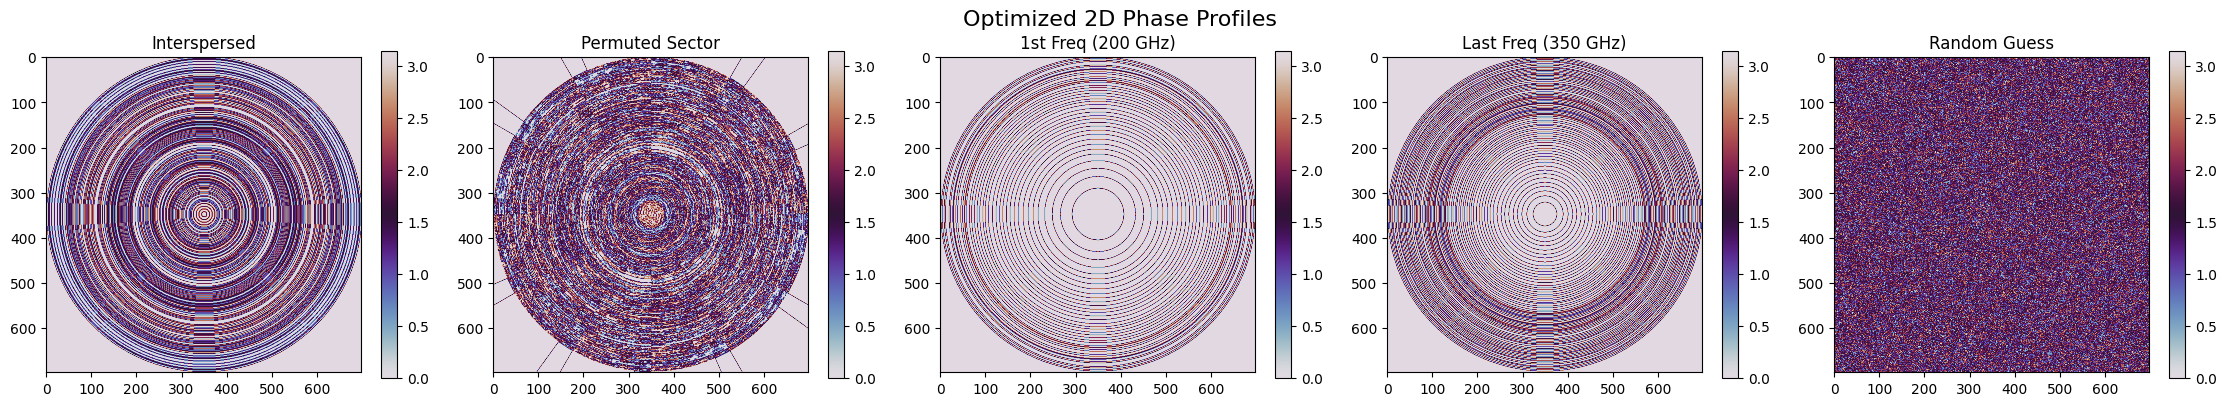

In [15]:
# ==========================================
# PLOTTING RESULTS
# ==========================================

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, optimized_phases, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Optimized 2D Phase Profiles", fontsize=16)
plt.tight_layout()
plt.show()


Generating binary DOE cross-section plots (ASM)...
Processing lens: Interspersed
Processing lens: Permuted Sector
Processing lens: 1st Freq (200 GHz)
Processing lens: Last Freq (350 GHz)
Processing lens: Random Guess


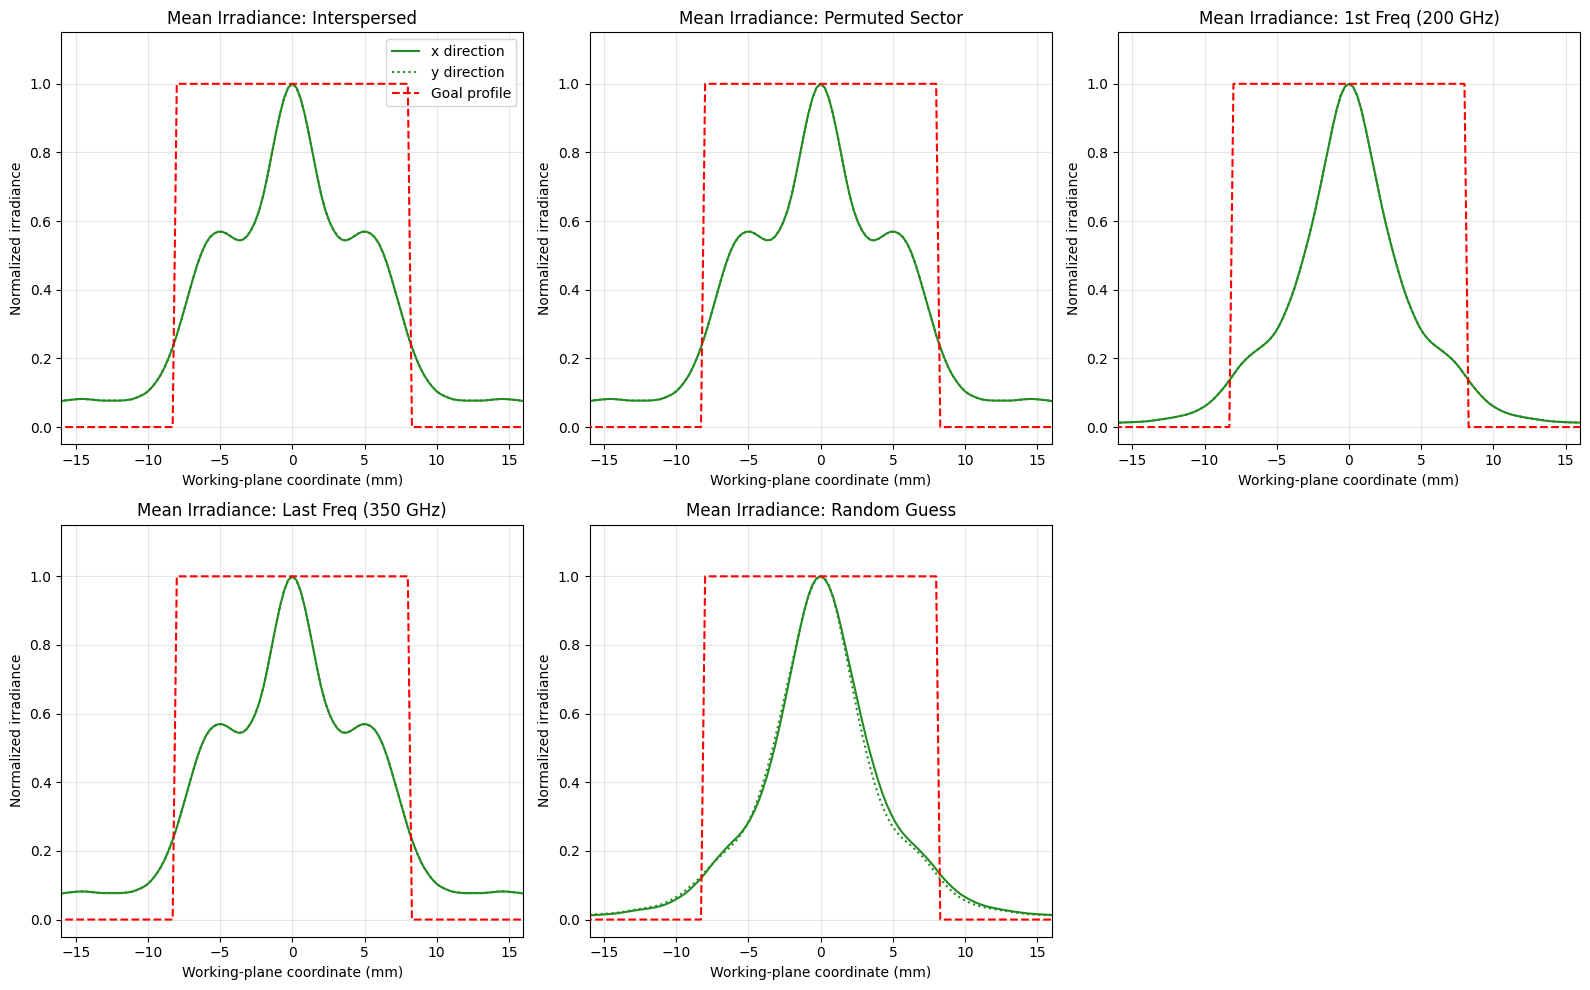

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CROSS-SECTION IRRADIANCE:
# BINARY DOE - ASM WORKING-PLANE COORDINATES
# ==========================================

print("\nGenerating binary DOE cross-section plots (ASM)...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_outputs)

if num_lenses == 0:
    raise ValueError(
        "optimized_freq_outputs is empty. "
        "Run the ASM optimization first."
    )

# Recover image size directly from stored ASM outputs
first_output = np.asarray(
    optimized_freq_outputs[0][0]
)

if first_output.ndim != 2 or first_output.shape[0] != first_output.shape[1]:
    raise ValueError(
        f"Expected square 2D intensity arrays. "
        f"Received shape {first_output.shape}."
    )

shape_2d = first_output.shape[0]
center_idx = shape_2d // 2

# Same spatial sampling as the DOE plane
dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Second frequency set
frequencies= [
    f0 + i * 30 * 1e9
    for i in range(6)
]

# Check output dimensions
for lens_idx, freq_Is in enumerate(optimized_freq_outputs):

    if len(freq_Is) != len(frequencies):
        raise ValueError(
            f"Lens {lens_idx} has {len(freq_Is)} frequency outputs, "
            f"but {len(frequencies)} were expected."
        )

    for f_idx, intensity in enumerate(freq_Is):

        if np.asarray(intensity).shape != (shape_2d, shape_2d):
            raise ValueError(
                f"Unexpected output shape for lens {lens_idx}, "
                f"frequency index {f_idx}."
            )


# ==========================================
# 2. ASM WORKING-PLANE SAMPLING
# ==========================================

# ASM preserves the spatial sampling interval
# between the DOE plane and the working plane.

x_work = (
    np.arange(shape_2d) - center_idx
) * dx

distance_mm = x_work * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(x_work) <= params['wgoal']
).astype(float)


# ==========================================
# 3. AVERAGE FREQUENCY OUTPUTS
# ==========================================

averaged_physical_outputs = []

fig2, axes2 = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes2 = axes2.flatten()

if num_lenses > len(axes2):
    raise ValueError(
        "More lenses than available subplot panels."
    )

for lens_idx, title in enumerate(titles[:num_lenses]):

    print(f"Processing lens: {title}")

    freq_Is = optimized_freq_outputs[lens_idx]

    # --------------------------------------
    # All frequency images already share
    # the same ASM physical coordinate grid.
    # No interpolation is necessary.
    # --------------------------------------

    avg_I_work = np.mean(
        np.stack(
            [np.asarray(I_f) for I_f in freq_Is],
            axis=0
        ),
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_work
    )


    # ======================================
    # 4. CROSS-SECTION EXTRACTION
    # ======================================

    I_norm = avg_I_work / (
        np.max(avg_I_work) + 1e-12
    )

    # Horizontal and vertical central cuts
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]


    # ======================================
    # 5. PLOT
    # ======================================

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile',
        zorder=10
    )

    ax.set_title(
        f"Mean Irradiance: {title}"
    )

    ax.set_xlabel(
        "Working-plane coordinate (mm)"
    )

    ax.set_ylabel(
        "Normalized irradiance"
    )

    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(
        -0.05,
        1.15
    )

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# ==========================================
# 6. DISABLE UNUSED SUBPLOT AXES
# ==========================================

for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')


plt.tight_layout()
plt.show()


Generating binary DOE cross-section plots (ASM)...
Processing lens: Interspersed
Processing lens: Permuted Sector
Processing lens: 1st Freq (200 GHz)
Processing lens: Last Freq (350 GHz)
Processing lens: Random Guess


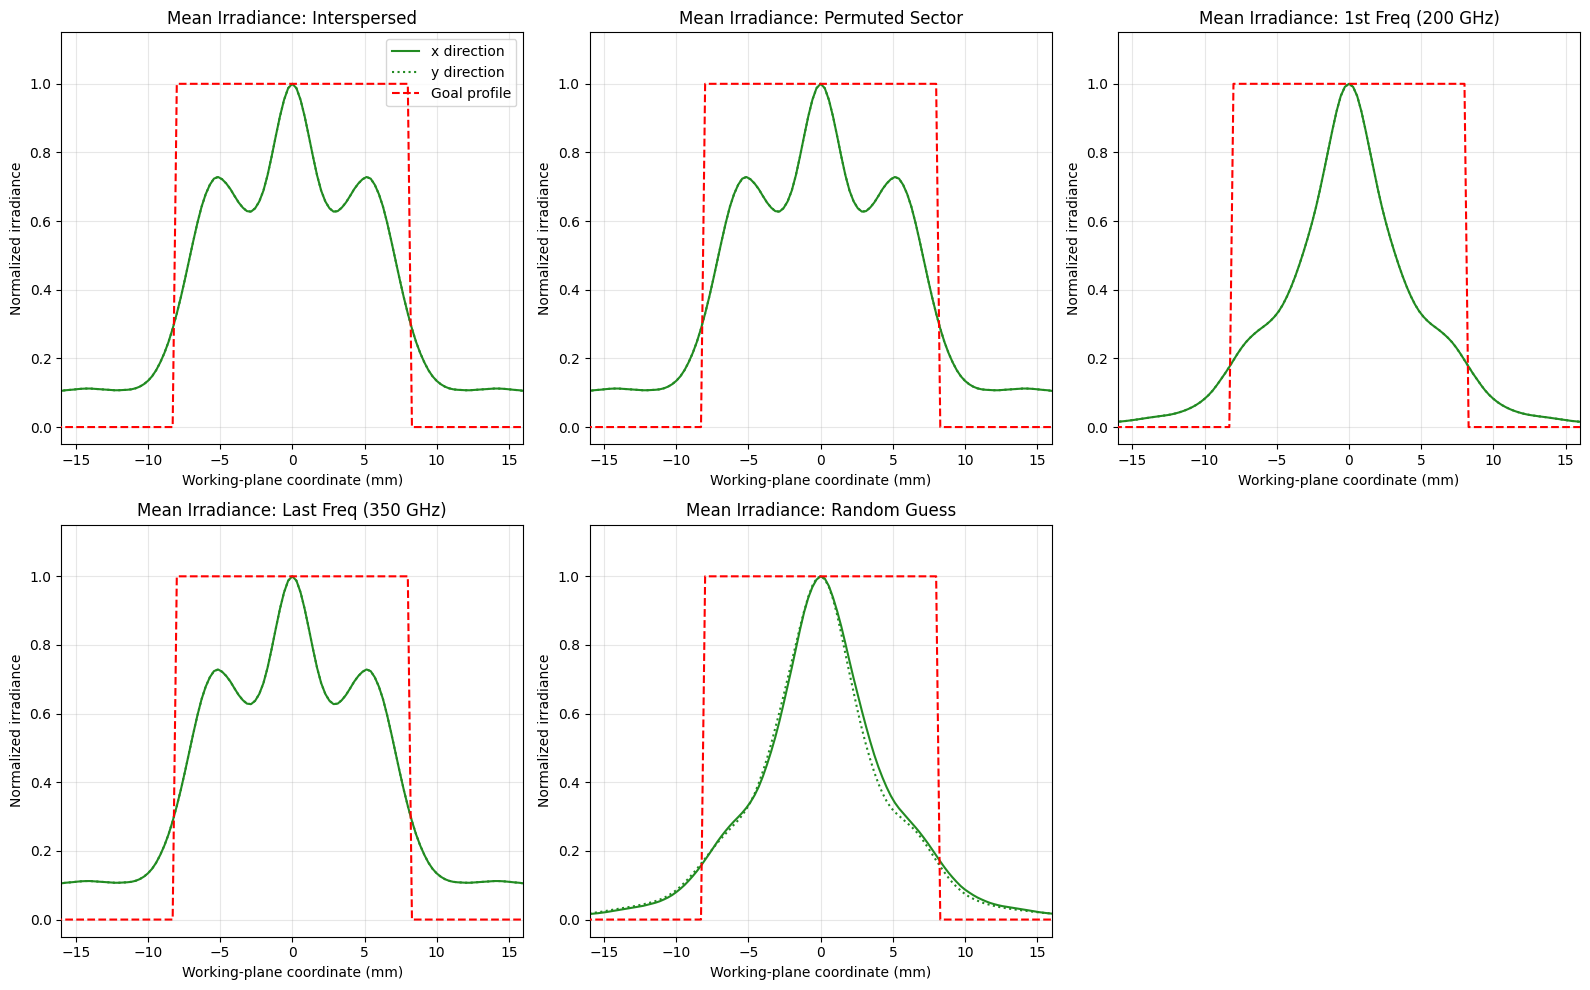

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CROSS-SECTION IRRADIANCE:
# BINARY DOE - ASM WORKING-PLANE COORDINATES
# ==========================================

print("\nGenerating binary DOE cross-section plots (ASM)...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_2_outputs)

if num_lenses == 0:
    raise ValueError(
        "optimized_freq_2_outputs is empty. "
        "Run the ASM optimization first."
    )

# Recover image size directly from stored ASM outputs
first_output = np.asarray(
    optimized_freq_2_outputs[0][0]
)

if first_output.ndim != 2 or first_output.shape[0] != first_output.shape[1]:
    raise ValueError(
        f"Expected square 2D intensity arrays. "
        f"Received shape {first_output.shape}."
    )

shape_2d = first_output.shape[0]
center_idx = shape_2d // 2

# Same spatial sampling as the DOE plane
dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]

# Check output dimensions
for lens_idx, freq_Is in enumerate(optimized_freq_2_outputs):

    if len(freq_Is) != len(frequencies_2):
        raise ValueError(
            f"Lens {lens_idx} has {len(freq_Is)} frequency outputs, "
            f"but {len(frequencies_2)} were expected."
        )

    for f_idx, intensity in enumerate(freq_Is):

        if np.asarray(intensity).shape != (shape_2d, shape_2d):
            raise ValueError(
                f"Unexpected output shape for lens {lens_idx}, "
                f"frequency index {f_idx}."
            )


# ==========================================
# 2. ASM WORKING-PLANE SAMPLING
# ==========================================

# ASM preserves the spatial sampling interval
# between the DOE plane and the working plane.

x_work = (
    np.arange(shape_2d) - center_idx
) * dx

distance_mm = x_work * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(x_work) <= params['wgoal']
).astype(float)


# ==========================================
# 3. AVERAGE FREQUENCY OUTPUTS
# ==========================================

averaged_physical_outputs = []

fig2, axes2 = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes2 = axes2.flatten()

if num_lenses > len(axes2):
    raise ValueError(
        "More lenses than available subplot panels."
    )

for lens_idx, title in enumerate(titles[:num_lenses]):

    print(f"Processing lens: {title}")

    freq_Is = optimized_freq_2_outputs[lens_idx]

    # --------------------------------------
    # All frequency images already share
    # the same ASM physical coordinate grid.
    # No interpolation is necessary.
    # --------------------------------------

    avg_I_work = np.mean(
        np.stack(
            [np.asarray(I_f) for I_f in freq_Is],
            axis=0
        ),
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_work
    )


    # ======================================
    # 4. CROSS-SECTION EXTRACTION
    # ======================================

    I_norm = avg_I_work / (
        np.max(avg_I_work) + 1e-12
    )

    # Horizontal and vertical central cuts
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]


    # ======================================
    # 5. PLOT
    # ======================================

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile',
        zorder=10
    )

    ax.set_title(
        f"Mean Irradiance: {title}"
    )

    ax.set_xlabel(
        "Working-plane coordinate (mm)"
    )

    ax.set_ylabel(
        "Normalized irradiance"
    )

    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(
        -0.05,
        1.15
    )

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# ==========================================
# 6. DISABLE UNUSED SUBPLOT AXES
# ==========================================

for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')


plt.tight_layout()
plt.show()



Generating per-frequency ASM plots...


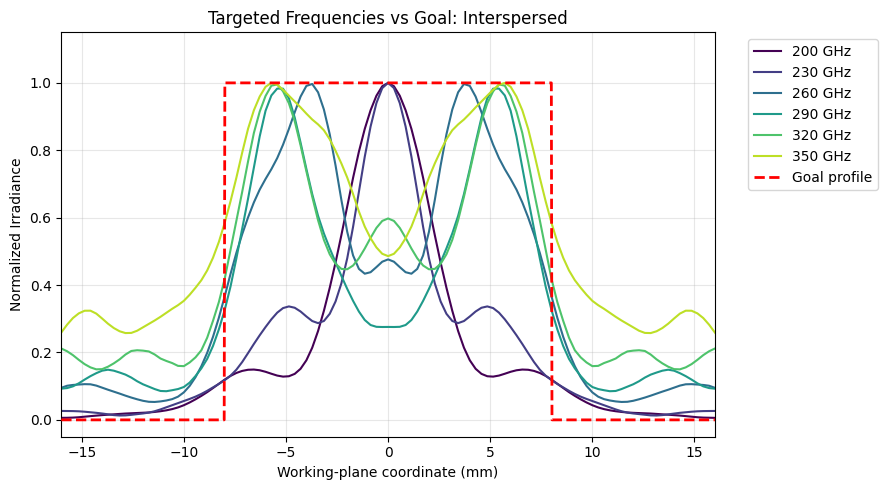

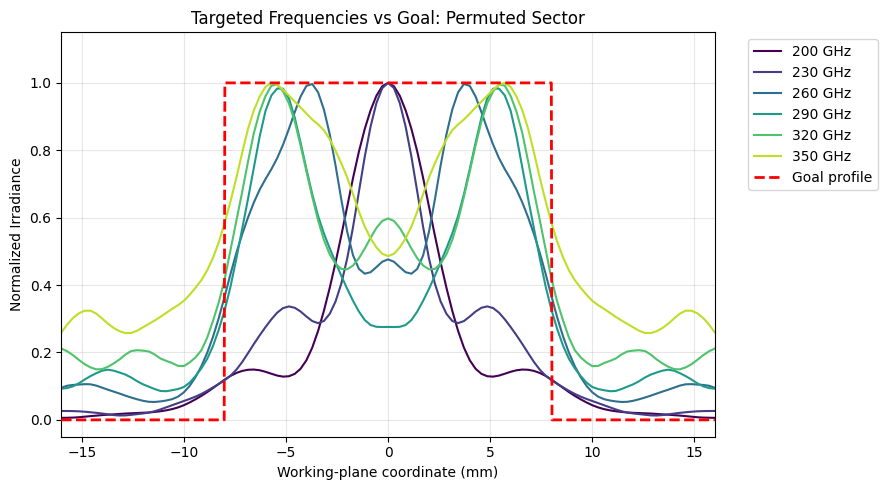

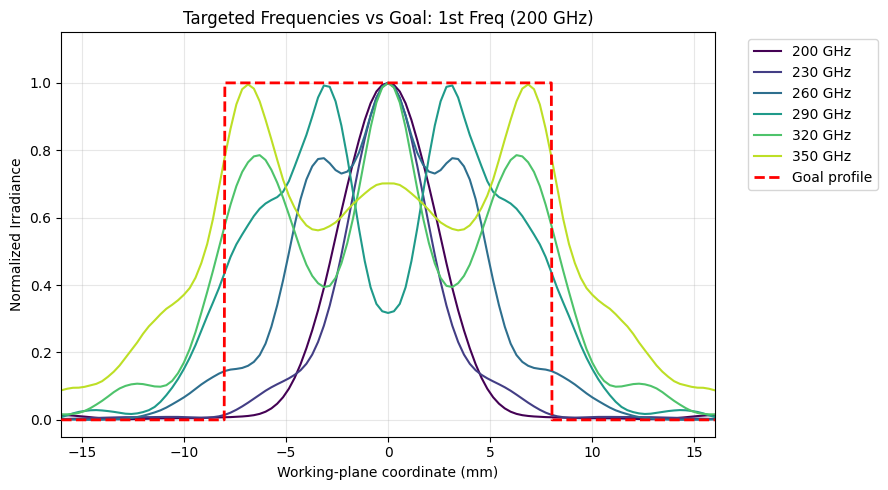

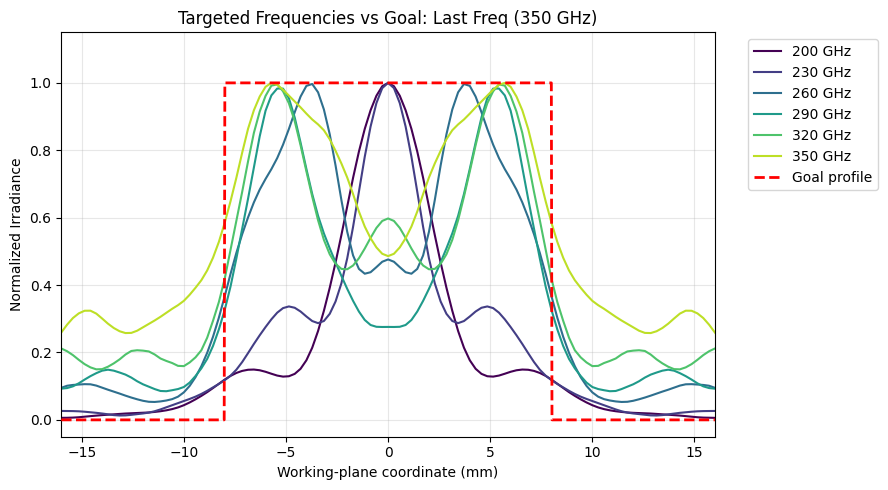

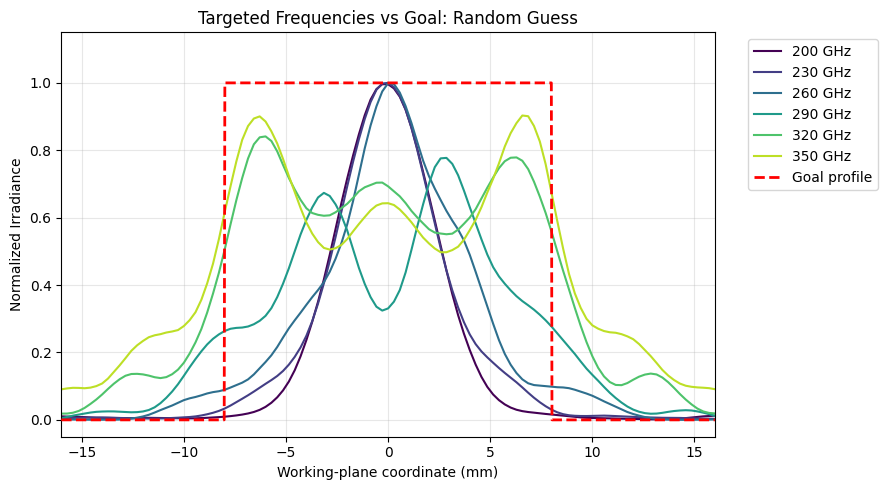

In [18]:
# ==========================================
# PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# BINARY DOE - ASM PROPAGATION
# Physical working-plane coordinates
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

print("\nGenerating per-frequency ASM plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_outputs)

if num_lenses == 0:
    raise ValueError(
        "optimized_freq_outputs is empty. Run the ASM optimization first."
    )

# Recover output dimensions
first_output = np.asarray(optimized_freq_outputs[0][0])

if first_output.ndim != 2 or first_output.shape[0] != first_output.shape[1]:
    raise ValueError(
        f"Expected square 2D intensity arrays. Received shape {first_output.shape}."
    )

shape_2d = first_output.shape[0]
center_idx = shape_2d // 2

# ASM preserves the transverse sampling interval
# from the DOE plane to the working plane.
dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Frequencies used in the binary optimization
frequencies = [
    f0 + i * 30e9 for i in range(6)
]

# Check stored outputs
for lens_idx, freq_outputs in enumerate(optimized_freq_outputs):

    if len(freq_outputs) != len(frequencies):
        raise ValueError(
            f"Lens {lens_idx} has {len(freq_outputs)} frequency outputs, "
            f"but {len(frequencies)} were expected."
        )

    for f_idx, intensity in enumerate(freq_outputs):

        if np.asarray(intensity).shape != (shape_2d, shape_2d):
            raise ValueError(
                f"Unexpected output shape for lens {lens_idx}, "
                f"frequency index {f_idx}."
            )

if len(titles) < num_lenses:
    raise ValueError(
        f"There are {num_lenses} lens outputs but only {len(titles)} titles."
    )


# ==========================================
# 2. ASM WORKING-PLANE COORDINATES
# ==========================================

# All frequencies share the same physical sampling grid:
# Delta x_working = Delta x_DOE = dx.

distance_mm = (
    np.arange(shape_2d) - center_idx
) * dx * 1000


# ==========================================
# 3. CONTINUOUS PHYSICAL TARGET PROFILE
# ==========================================

distance_mm_goal = np.linspace(
    -2 * wgoal_mm,
    2 * wgoal_mm,
    1000
)

goal_profile = (
    np.abs(distance_mm_goal) <= wgoal_mm
).astype(float)


# ==========================================
# 4. PLOT EACH LENS
# ==========================================

for lens_idx, (freq_outputs, title) in enumerate(
    zip(optimized_freq_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Distinct color for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies))
    )

    # --------------------------------------
    # Plot each frequency's central cut
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_outputs, frequencies)
    ):

        freq_I = np.asarray(freq_I)

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central horizontal cross-section
        x_slice = I_norm[center_idx, :]

        # All ASM outputs share the same physical grid
        plt.plot(
            distance_mm,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Plot circular uniform target
    # --------------------------------------

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Working-plane coordinate (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



Generating per-frequency ASM plots...


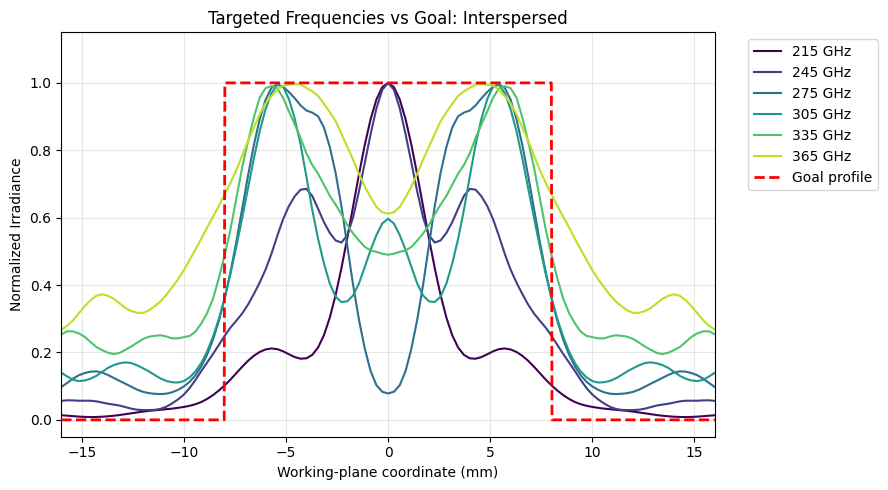

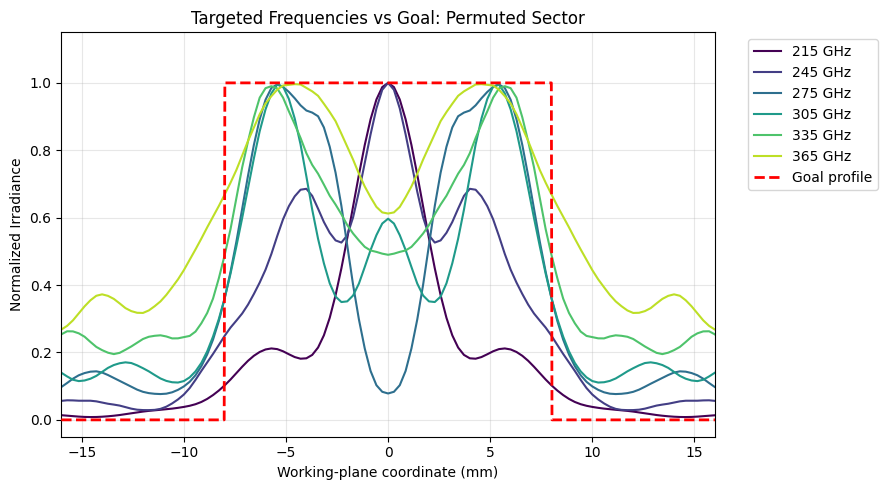

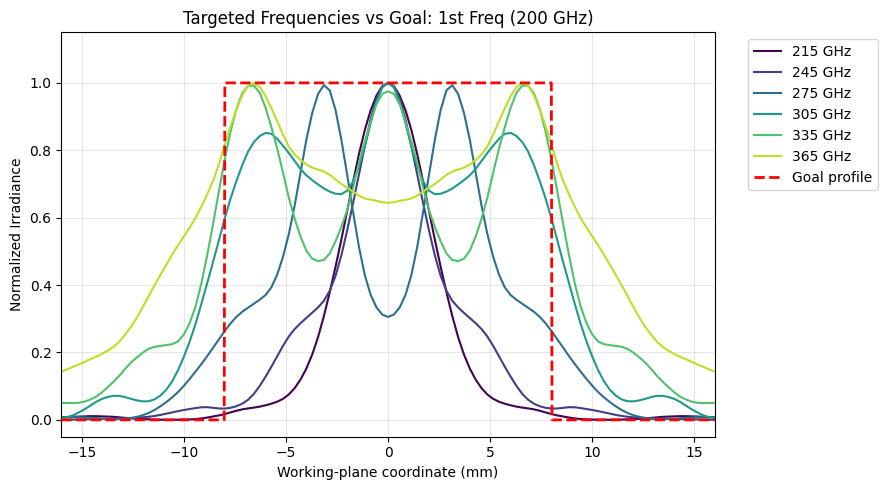

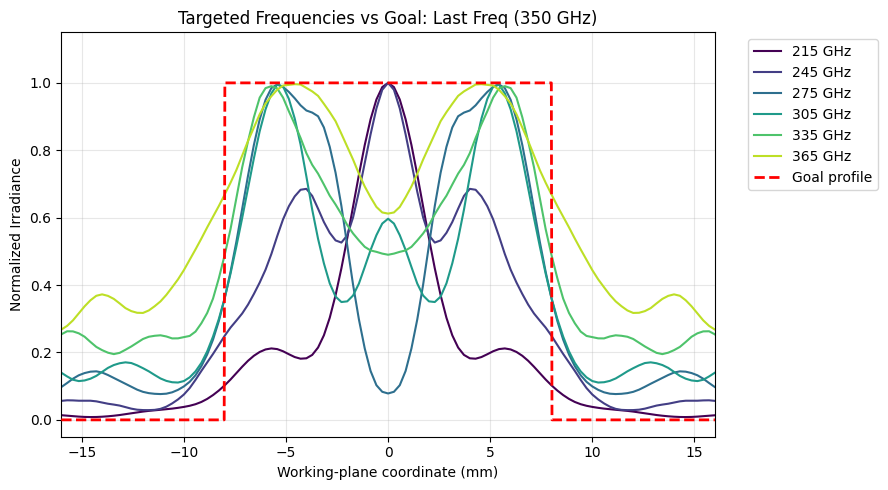

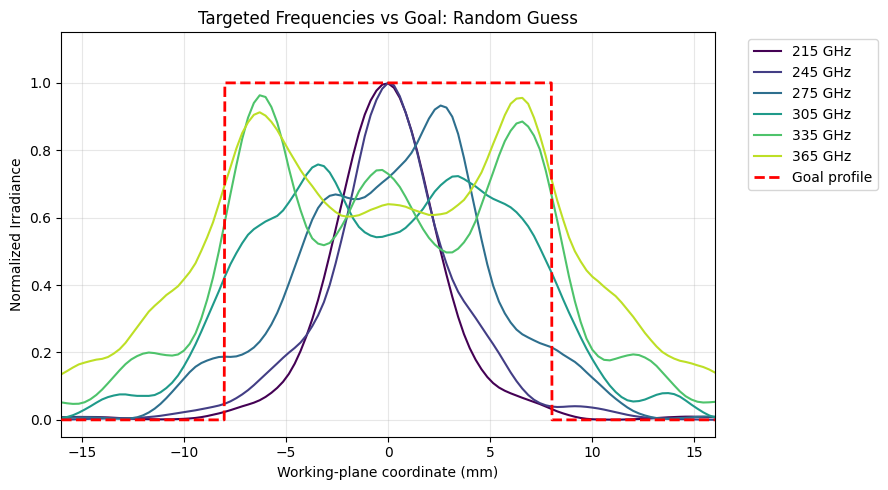

In [19]:
# ==========================================
# PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# BINARY DOE - ASM PROPAGATION
# Physical working-plane coordinates
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

print("\nGenerating per-frequency ASM plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_2_outputs)

if num_lenses == 0:
    raise ValueError(
        "optimized_freq_2_outputs is empty. Run the ASM optimization first."
    )

# Recover output dimensions
first_output = np.asarray(optimized_freq_2_outputs[0][0])

if first_output.ndim != 2 or first_output.shape[0] != first_output.shape[1]:
    raise ValueError(
        f"Expected square 2D intensity arrays. Received shape {first_output.shape}."
    )

shape_2d = first_output.shape[0]
center_idx = shape_2d // 2

# ASM preserves the transverse sampling interval
# from the DOE plane to the working plane.
dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Frequencies used in the binary optimization
frequencies = [
    f0 + 15 * 1e9 + i * 30 * 1e9
   for i in range(6)
]

# Check stored outputs
for lens_idx, freq_outputs in enumerate(optimized_freq_2_outputs):

    if len(freq_outputs) != len(frequencies):
        raise ValueError(
            f"Lens {lens_idx} has {len(freq_outputs)} frequency outputs, "
            f"but {len(frequencies)} were expected."
        )

    for f_idx, intensity in enumerate(freq_outputs):

        if np.asarray(intensity).shape != (shape_2d, shape_2d):
            raise ValueError(
                f"Unexpected output shape for lens {lens_idx}, "
                f"frequency index {f_idx}."
            )

if len(titles) < num_lenses:
    raise ValueError(
        f"There are {num_lenses} lens outputs but only {len(titles)} titles."
    )


# ==========================================
# 2. ASM WORKING-PLANE COORDINATES
# ==========================================

# All frequencies share the same physical sampling grid:
# Delta x_working = Delta x_DOE = dx.

distance_mm = (
    np.arange(shape_2d) - center_idx
) * dx * 1000


# ==========================================
# 3. CONTINUOUS PHYSICAL TARGET PROFILE
# ==========================================

distance_mm_goal = np.linspace(
    -2 * wgoal_mm,
    2 * wgoal_mm,
    1000
)

goal_profile = (
    np.abs(distance_mm_goal) <= wgoal_mm
).astype(float)


# ==========================================
# 4. PLOT EACH LENS
# ==========================================

for lens_idx, (freq_outputs, title) in enumerate(
    zip(optimized_freq_2_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Distinct color for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies))
    )

    # --------------------------------------
    # Plot each frequency's central cut
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_outputs, frequencies)
    ):

        freq_I = np.asarray(freq_I)

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central horizontal cross-section
        x_slice = I_norm[center_idx, :]

        # All ASM outputs share the same physical grid
        plt.plot(
            distance_mm,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Plot circular uniform target
    # --------------------------------------

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Working-plane coordinate (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [20]:

# ==========================================
# FOCUSING EFFICIENCY AT EACH FREQUENCY
# ==========================================

print("\nFocusing efficiency per frequency:")

for lens_idx, title in enumerate(titles):

    print(f"\nLens: {title}")

    for f_idx, f in enumerate(frequencies):

        I_f = torch.as_tensor(
            optimized_freq_outputs[lens_idx][f_idx],
            device=device,
            dtype=torch.float32
        )

        dxf = focal_plane_spacings[f_idx]

        # Target power
        P_target = (
            torch.sum(I_f * target_masks[f_idx])
            * dxf**2
        )

        # Background power
        P_background = (
            torch.sum(
                I_f * background_masks[f_idx]
            ) * dxf**2
        )

        efficiency = P_target / P_in

        print(
            f"{f/1e9:.0f} GHz | "
            f"Target efficiency: {efficiency.item():.4f} | "
            f"Background power: {P_background.item()/P_in.item():.4f}"
        )



Focusing efficiency per frequency:

Lens: Interspersed
215 GHz | Target efficiency: 0.4990 | Background power: 0.4647
245 GHz | Target efficiency: 0.4834 | Background power: 0.4864
275 GHz | Target efficiency: 0.4505 | Background power: 0.5278
305 GHz | Target efficiency: 0.4053 | Background power: 0.5806
335 GHz | Target efficiency: 0.3552 | Background power: 0.6369
365 GHz | Target efficiency: 0.3101 | Background power: 0.6869

Lens: Permuted Sector
215 GHz | Target efficiency: 0.4990 | Background power: 0.4647
245 GHz | Target efficiency: 0.4834 | Background power: 0.4864
275 GHz | Target efficiency: 0.4505 | Background power: 0.5278
305 GHz | Target efficiency: 0.4053 | Background power: 0.5806
335 GHz | Target efficiency: 0.3552 | Background power: 0.6369
365 GHz | Target efficiency: 0.3101 | Background power: 0.6869

Lens: 1st Freq (200 GHz)
215 GHz | Target efficiency: 0.4957 | Background power: 0.4525
245 GHz | Target efficiency: 0.5571 | Background power: 0.4007
275 GHz | Tar